# Apprentissage fédéré : entraîner un modèle sans centraliser les données

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/cercle-des-experts/blob/main/ml-classique-et-deep-learning/guide-pratique-apprentissage-federe/guide-pratique-apprentissage-federe.ipynb)

📖 **Le mini-cours complet** : [Apprentissage Fédéré : Entraîne l'IA, Sécurise les Données](https://www.monshotdata.com/p/guide-pratique-apprentissage-federe)

🧭 **Le cours** : [ML classique et Deep Learning › 2.4 Architectures et entraînement en Deep Learning](https://www.monshotdata.com/mini-cours/ml-classique-et-deep-learning#h2sc24)

---

Et si tu pouvais entraîner un modèle sur les données de milliers d'appareils **sans jamais les rassembler** ? C'est le principe de l'**apprentissage fédéré** : on envoie le modèle aux données, pas l'inverse. Tu vas coder le cycle complet (distribution, entraînement local, agrégation) sur CIFAR-10, puis voir ce qui change quand les données des clients ne se ressemblent plus.

**À la fin de ce notebook, tu sauras :**

- comment fonctionne un tour de communication : copie du modèle, entraînement local, moyenne des mises à jour ;
- pourquoi des données **non IID** (chaque client voit des classes différentes) dégradent le modèle global ;
- tester une piste de correction (un petit jeu de données commun) et mesurer honnêtement si elle aide.


### Avant de lancer

CIFAR-10 (≈ 170 Mo) est téléchargé automatiquement dans `./data`. Pas besoin de GPU, mais le notebook entraîne plusieurs modèles de suite : avec `num_rounds = 30` (valeur par défaut), compte une trentaine de minutes sur un CPU (bien moins avec un GPU Colab). Tu peux descendre à `num_rounds = 10` pour une première lecture, ou monter à 150 pour des courbes plus abouties.

**Corrections par rapport à la version diffusée avec le mini-cours :** les « clients » étaient en réalité le même objet que le modèle global (`[global_model for _ in range(num_clients)]`), si bien que les clients s'entraînaient l'un après l'autre sur le même modèle au lieu de partir chacun d'une copie, et que la moyenne ne faisait rien. Chaque client travaille maintenant sur une vraie copie (`deepcopy`) avec son propre optimiseur, ce qui est le véritable algorithme FedAvg. Les précisions que tu obtiens peuvent donc différer de celles du mini-cours. De plus, le découpage non IID donne désormais à chaque image un seul propriétaire, et le calcul des indices est instantané au lieu de durer plusieurs minutes.

🧪 *Testé le 20 novembre 2026 avec Python 3.13, PyTorch 2.x et torchvision : exécution complète de haut en bas sur CPU (environ 28 minutes, `num_rounds = 30`). Les sorties affichées viennent de cette exécution ; les chiffres varient légèrement d'un lancement à l'autre.*

## 1. Mise en place

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from torch.utils.data import Subset
from copy import deepcopy
from torch.utils.data import DataLoader

sns.set()

import warnings
warnings.filterwarnings('ignore', message='.*dtype.*align.*')

## 2. Les données : CIFAR-10 réparti entre 8 clients

CIFAR-10 : 50 000 images en couleur (32×32) réparties en 10 classes (avion, chat, camion…). On les distribue **au hasard et à parts égales** entre `num_clients` clients : chacun garde ses images « sur son appareil ». Le jeu de test, lui, reste chez le serveur pour mesurer le modèle global.

`num_rounds` est le nombre de **tours de communication** (l'équivalent des époques).

In [ ]:
num_clients = 8
batch_size = 64
num_rounds = 30

In [ ]:
transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Chargement de CIFAR10 en utilisant torchvision.datasets
traindata = torchvision.datasets.CIFAR10('./data', train=True, download=True,
                       transform= transform_train)

# Division des données d'entraînement en num_clients, chaque client ayant un nombre égal d'images
traindata_split = torch.utils.data.random_split(traindata, [int(traindata.data.shape[0] / num_clients) for _ in range(num_clients)])

# Création d'un chargeur PyTorch pour un modèle d'apprentissage profond
trainloader = [torch.utils.data.DataLoader(x, batch_size=batch_size, shuffle=True) for x in traindata_split]

# Normalisation des images de test
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Chargement des images de test et conversion en test_loader
testloader = torch.utils.data.DataLoader(
        torchvision.datasets.CIFAR10('./data',
                         train=False,
                         transform=transform_test),
                         batch_size=batch_size, shuffle=True)

## 3. Le réseau

Un simple perceptron à 4 couches, sans convolution : le but est de comprendre l'apprentissage fédéré, pas de battre un record sur CIFAR-10. Les précisions resteront donc modestes.

In [ ]:
class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        self.fc1 = nn.Linear(32 * 32 * 3, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = self.fc4(x)
        return x 

## 4. Évaluation

Précision du modèle sur les 10 000 images de test.

In [ ]:
def evaluate(model):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data in testloader:
            inputs, labels = data
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

## 5. L'entraînement d'un client

Un client reçoit un modèle, l'entraîne sur ses données locales (une époque par défaut) et le renvoie. Ses données ne quittent jamais l'appareil.

In [ ]:
def client_forward_pass(client_model, criterion, optimizer, trainloader, epochs=1):
    client_model.train()
    total_loss = 0
    for epoch in range(epochs):
        epoch_loss = 0
        for data in trainloader:
            inputs, labels = data
            optimizer.zero_grad()
            output = client_model(inputs)
            loss = criterion(output, labels)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            
        total_loss += epoch_loss
    return client_model, total_loss/epochs

## 6. L'agrégation côté serveur

Le serveur ne voit que les **poids** des modèles clients. Il en fait la **moyenne** paramètre par paramètre : c'est l'algorithme **FedAvg** (*Federated Averaging*).

In [ ]:
def server_aggregate(global_model, client_models):

    global_dict = global_model.state_dict()
       
    for k in global_dict.keys():
        global_dict[k] = torch.stack([client_models[i].state_dict()[k].float() for i in range(len(client_models))], 0).mean(0)
    
    global_model.load_state_dict(global_dict)

## 7. Instancier le modèle global et la fonction de perte

Chaque client aura son propre optimiseur, créé à chaque tour sur sa copie du modèle.

In [ ]:
global_model = SimpleNet()
criterion = nn.CrossEntropyLoss()

## 8. Entraîner avec tous les clients

À chaque tour : (1) le serveur envoie **une copie** du modèle global à chaque client, (2) chaque client s'entraîne localement, (3) le serveur moyenne les modèles reçus. La précision du modèle global doit augmenter au fil des tours.

In [ ]:
for round_no in range(num_rounds):

    total_loss = 0

    # 1. Le serveur envoie une COPIE indépendante du modèle global à chaque client
    client_models = [deepcopy(global_model) for _ in range(num_clients)]

    # 2. Chaque client entraîne sa copie sur ses propres données
    for i in range(num_clients):
        optimizer = optim.Adam(client_models[i].parameters(), lr=0.001)
        client_models[i], local_loss = client_forward_pass(client_models[i], criterion, optimizer, trainloader[i])
        total_loss += local_loss

    # 3. Le serveur agrège (moyenne) les modèles des clients
    server_aggregate(global_model, client_models)

    print("Tour :", round_no + 1, "| Perte :", round(total_loss, 3), "| Précision :", round(evaluate(global_model), 4))

Tour : 1 | Perte : 1492.694 | Précision : 0.3531
Tour : 2 | Perte : 1390.004 | Précision : 0.4265
Tour : 3 | Perte : 1324.546 | Précision : 0.4538
Tour : 4 | Perte : 1283.066 | Précision : 0.4717
Tour : 5 | Perte : 1243.339 | Précision : 0.4846
Tour : 6 | Perte : 1211.914 | Précision : 0.4938
Tour : 7 | Perte : 1179.939 | Précision : 0.5024
Tour : 8 | Perte : 1156.155 | Précision : 0.5092
Tour : 9 | Perte : 1132.717 | Précision : 0.5136
Tour : 10 | Perte : 1108.186 | Précision : 0.5202
Tour : 11 | Perte : 1086.288 | Précision : 0.5256
Tour : 12 | Perte : 1069.657 | Précision : 0.5329
Tour : 13 | Perte : 1047.602 | Précision : 0.5355
Tour : 14 | Perte : 1031.9 | Précision : 0.5403
Tour : 15 | Perte : 1011.966 | Précision : 0.5413
Tour : 16 | Perte : 995.262 | Précision : 0.5435
Tour : 17 | Perte : 976.543 | Précision : 0.5479
Tour : 18 | Perte : 964.709 | Précision : 0.5498
Tour : 19 | Perte : 946.441 | Précision : 0.5508
Tour : 20 | Perte : 929.048 | Précision : 0.5552
Tour : 21 | Pert

## 9. Entraîner avec une partie seulement des clients

En pratique, à chaque tour, seule une fraction des appareils est disponible (batterie, réseau…). On tire donc `num_selected` clients au hasard à chaque tour. Le reste du code est identique.

In [ ]:
global_model = SimpleNet()
num_selected = 6

for round_no in range(num_rounds):

    total_loss = 0

    # Tirage des clients disponibles pour ce tour
    selected_client_ids = np.random.permutation(num_clients)[:num_selected]

    # Copie du modèle global pour chaque client sélectionné
    client_models = [deepcopy(global_model) for _ in range(num_selected)]

    for i, client_id in enumerate(selected_client_ids):
        optimizer = optim.Adam(client_models[i].parameters(), lr=0.001)
        client_models[i], local_loss = client_forward_pass(client_models[i], criterion, optimizer, trainloader[client_id])
        total_loss += local_loss

    # Agrégation côté serveur
    server_aggregate(global_model, client_models)

    print("Tour :", round_no + 1, "| Perte :", round(total_loss, 3), "| Précision :", round(evaluate(global_model), 4))

Tour : 1 | Perte : 1117.816 | Précision : 0.3749
Tour : 2 | Perte : 1039.051 | Précision : 0.4285
Tour : 3 | Perte : 997.787 | Précision : 0.4605
Tour : 4 | Perte : 961.744 | Précision : 0.4711
Tour : 5 | Perte : 932.596 | Précision : 0.4833
Tour : 6 | Perte : 909.829 | Précision : 0.4917
Tour : 7 | Perte : 885.856 | Précision : 0.4985
Tour : 8 | Perte : 869.151 | Précision : 0.5052
Tour : 9 | Perte : 847.673 | Précision : 0.5152
Tour : 10 | Perte : 836.142 | Précision : 0.5178
Tour : 11 | Perte : 816.143 | Précision : 0.5246
Tour : 12 | Perte : 802.8 | Précision : 0.5318
Tour : 13 | Perte : 791.161 | Précision : 0.5334
Tour : 14 | Perte : 781.589 | Précision : 0.5359
Tour : 15 | Perte : 764.276 | Précision : 0.5365
Tour : 16 | Perte : 748.001 | Précision : 0.5418
Tour : 17 | Perte : 746.575 | Précision : 0.5462
Tour : 18 | Perte : 725.044 | Précision : 0.5481
Tour : 19 | Perte : 722.161 | Précision : 0.5438
Tour : 20 | Perte : 698.858 | Précision : 0.547
Tour : 21 | Perte : 694.511 | 

## 10. Point de comparaison : l'entraînement traditionnel

Pour savoir ce que l'on perd à ne pas centraliser, on entraîne le même réseau de façon classique, avec **toutes** les données réunies au même endroit. Cette comparaison n'est pas réaliste (dans la vraie vie, on n'a jamais accès à toutes les données), mais elle donne une référence. Ici, elle ne dure que 6 époques, alors que l'apprentissage fédéré fait 30 tours : ne cherche donc pas un classement strict, l'important est l'ordre de grandeur (autour de 54 %).

In [ ]:
global_model = SimpleNet()
criterion = nn.CrossEntropyLoss()
opt = optim.Adam(global_model.parameters(), lr=0.001)
central_loader = DataLoader(traindata, batch_size=batch_size, shuffle=True)

In [ ]:
global_model.train()

for epoch in range(6):
    total_loss = 0
    for inputs, labels in central_loader:
        opt.zero_grad()
        output = global_model(inputs)
        loss = criterion(output, labels)
        loss.backward()
        opt.step()
        total_loss += loss.item()

    print("Époque :", epoch + 1, "| Perte :", round(total_loss, 3), "| Précision :", round(evaluate(global_model), 4))

Époque : 1 | Perte : 1296.477 | Précision : 0.4666
Époque : 2 | Perte : 1124.652 | Précision : 0.498
Époque : 3 | Perte : 1030.715 | Précision : 0.5196
Époque : 4 | Perte : 957.965 | Précision : 0.5162
Époque : 5 | Perte : 891.568 | Précision : 0.5404
Époque : 6 | Perte : 829.705 | Précision : 0.5407


## 11. Données IID : chaque client voit toutes les classes

**IID** = *indépendantes et identiquement distribuées*. Ici le découpage est aléatoire, donc chaque client a environ autant d'images de chaque classe. C'est le cas idéal.

In [ ]:
# Fonction pour tracer la distribution des étiquettes
def plot_label_distribution(subset, subset_index, ax, index):
    labels = [traindata.targets[j] for j in subset.indices]
    unique_labels, label_counts = torch.unique(torch.tensor(labels), return_counts=True)
    ax[index].bar(unique_labels.numpy(), label_counts.numpy(), color='#fe7c73')
    ax[index].set_title(f"Client {subset_index+1}", fontsize=20, weight="bold")
    ax[index].set_xticks(range(10))
    ax[index].set_ylabel("Nombre")

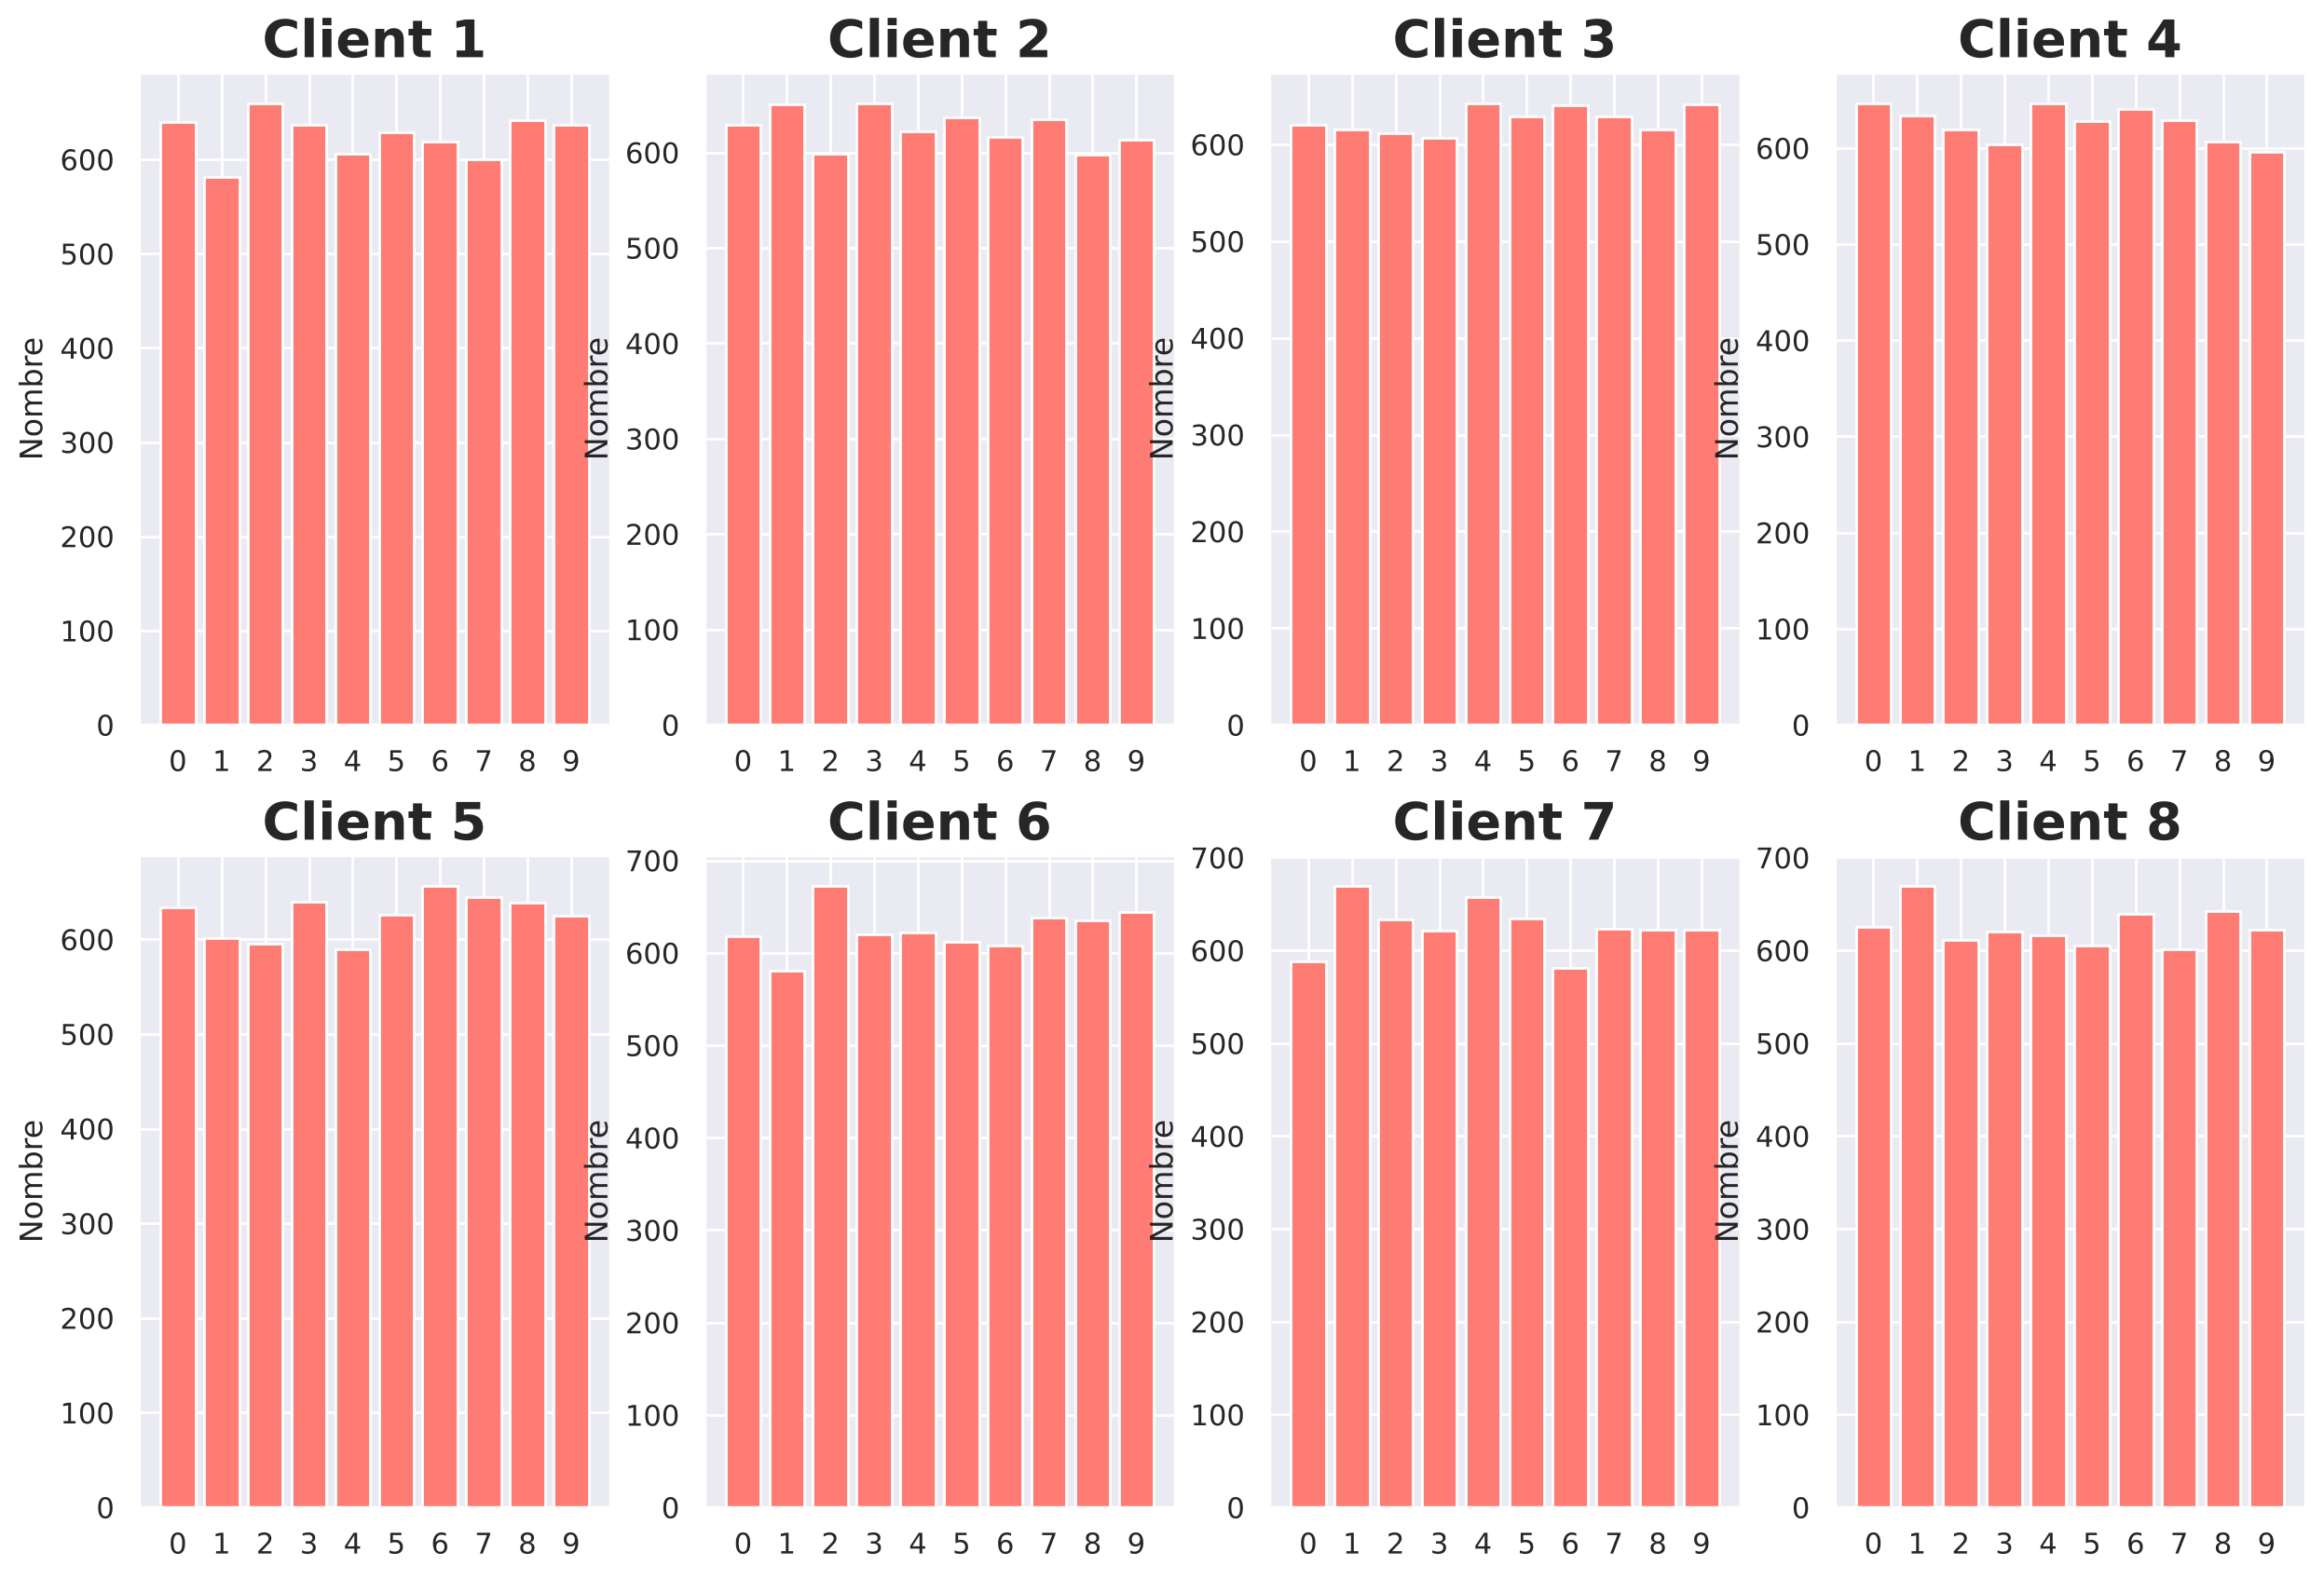

In [ ]:
fig, ax = plt.subplot_mosaic("ABCD;EFGH", figsize=(15, 10))

all_ax = list(ax.keys())
for i, subset in enumerate(traindata_split):
    plot_label_distribution(subset, i, ax, all_ax[i])

plt.show()

## 12. Données non IID : chaque client voit des classes différentes

Dans la réalité, les données des appareils ne se ressemblent pas : un utilisateur photographie surtout des chats, un autre des voitures. On le simule avec une table `distribution` : la ligne `i` donne le nombre d'images de chaque classe pour le client `i`. Chaque classe est répartie sur plusieurs clients, de façon très déséquilibrée (certains clients n'ont jamais vu certaines classes).

In [ ]:
##  ---> class

distribution = np.array([[1000,  200,  300,   0,     0,    0,  3000,  100, 1200,  100], 
                         [ 200, 1000,    0, 3000,  900,    0,     0, 1500,  600,    0],
                         [   0,  700,  300,    0,  300, 2500,   400,  600,    0,  200],
                         [ 500,    0,  600,  500, 1000, 1500,     0,  300, 1900,  300],
                         [   0,    0, 2200,  400,  300,  600,     0,  100,    0,  400],
                         [   0, 2000,  300,  100, 2500,  400,  1600,    0,  400,    0],
                         [ 300,  800,  300,  400,    0,    0,     0, 1900,  700, 3500],
                         [3000,  300, 1000,  600,    0,    0,     0,  500,  200,  500]])

In [ ]:
# Fonction pour tracer la distribution des étiquettes
def plot_label_distribution(client_data, ax, ax_index, index):

    ax[ax_index].bar(range(10), client_data, color='#fe7c73')
    ax[ax_index].set_title(f"Client {index+1}", fontsize=20, weight="bold")
    ax[ax_index].set_xticks(range(10))
    ax[ax_index].set_ylabel("Nombre")

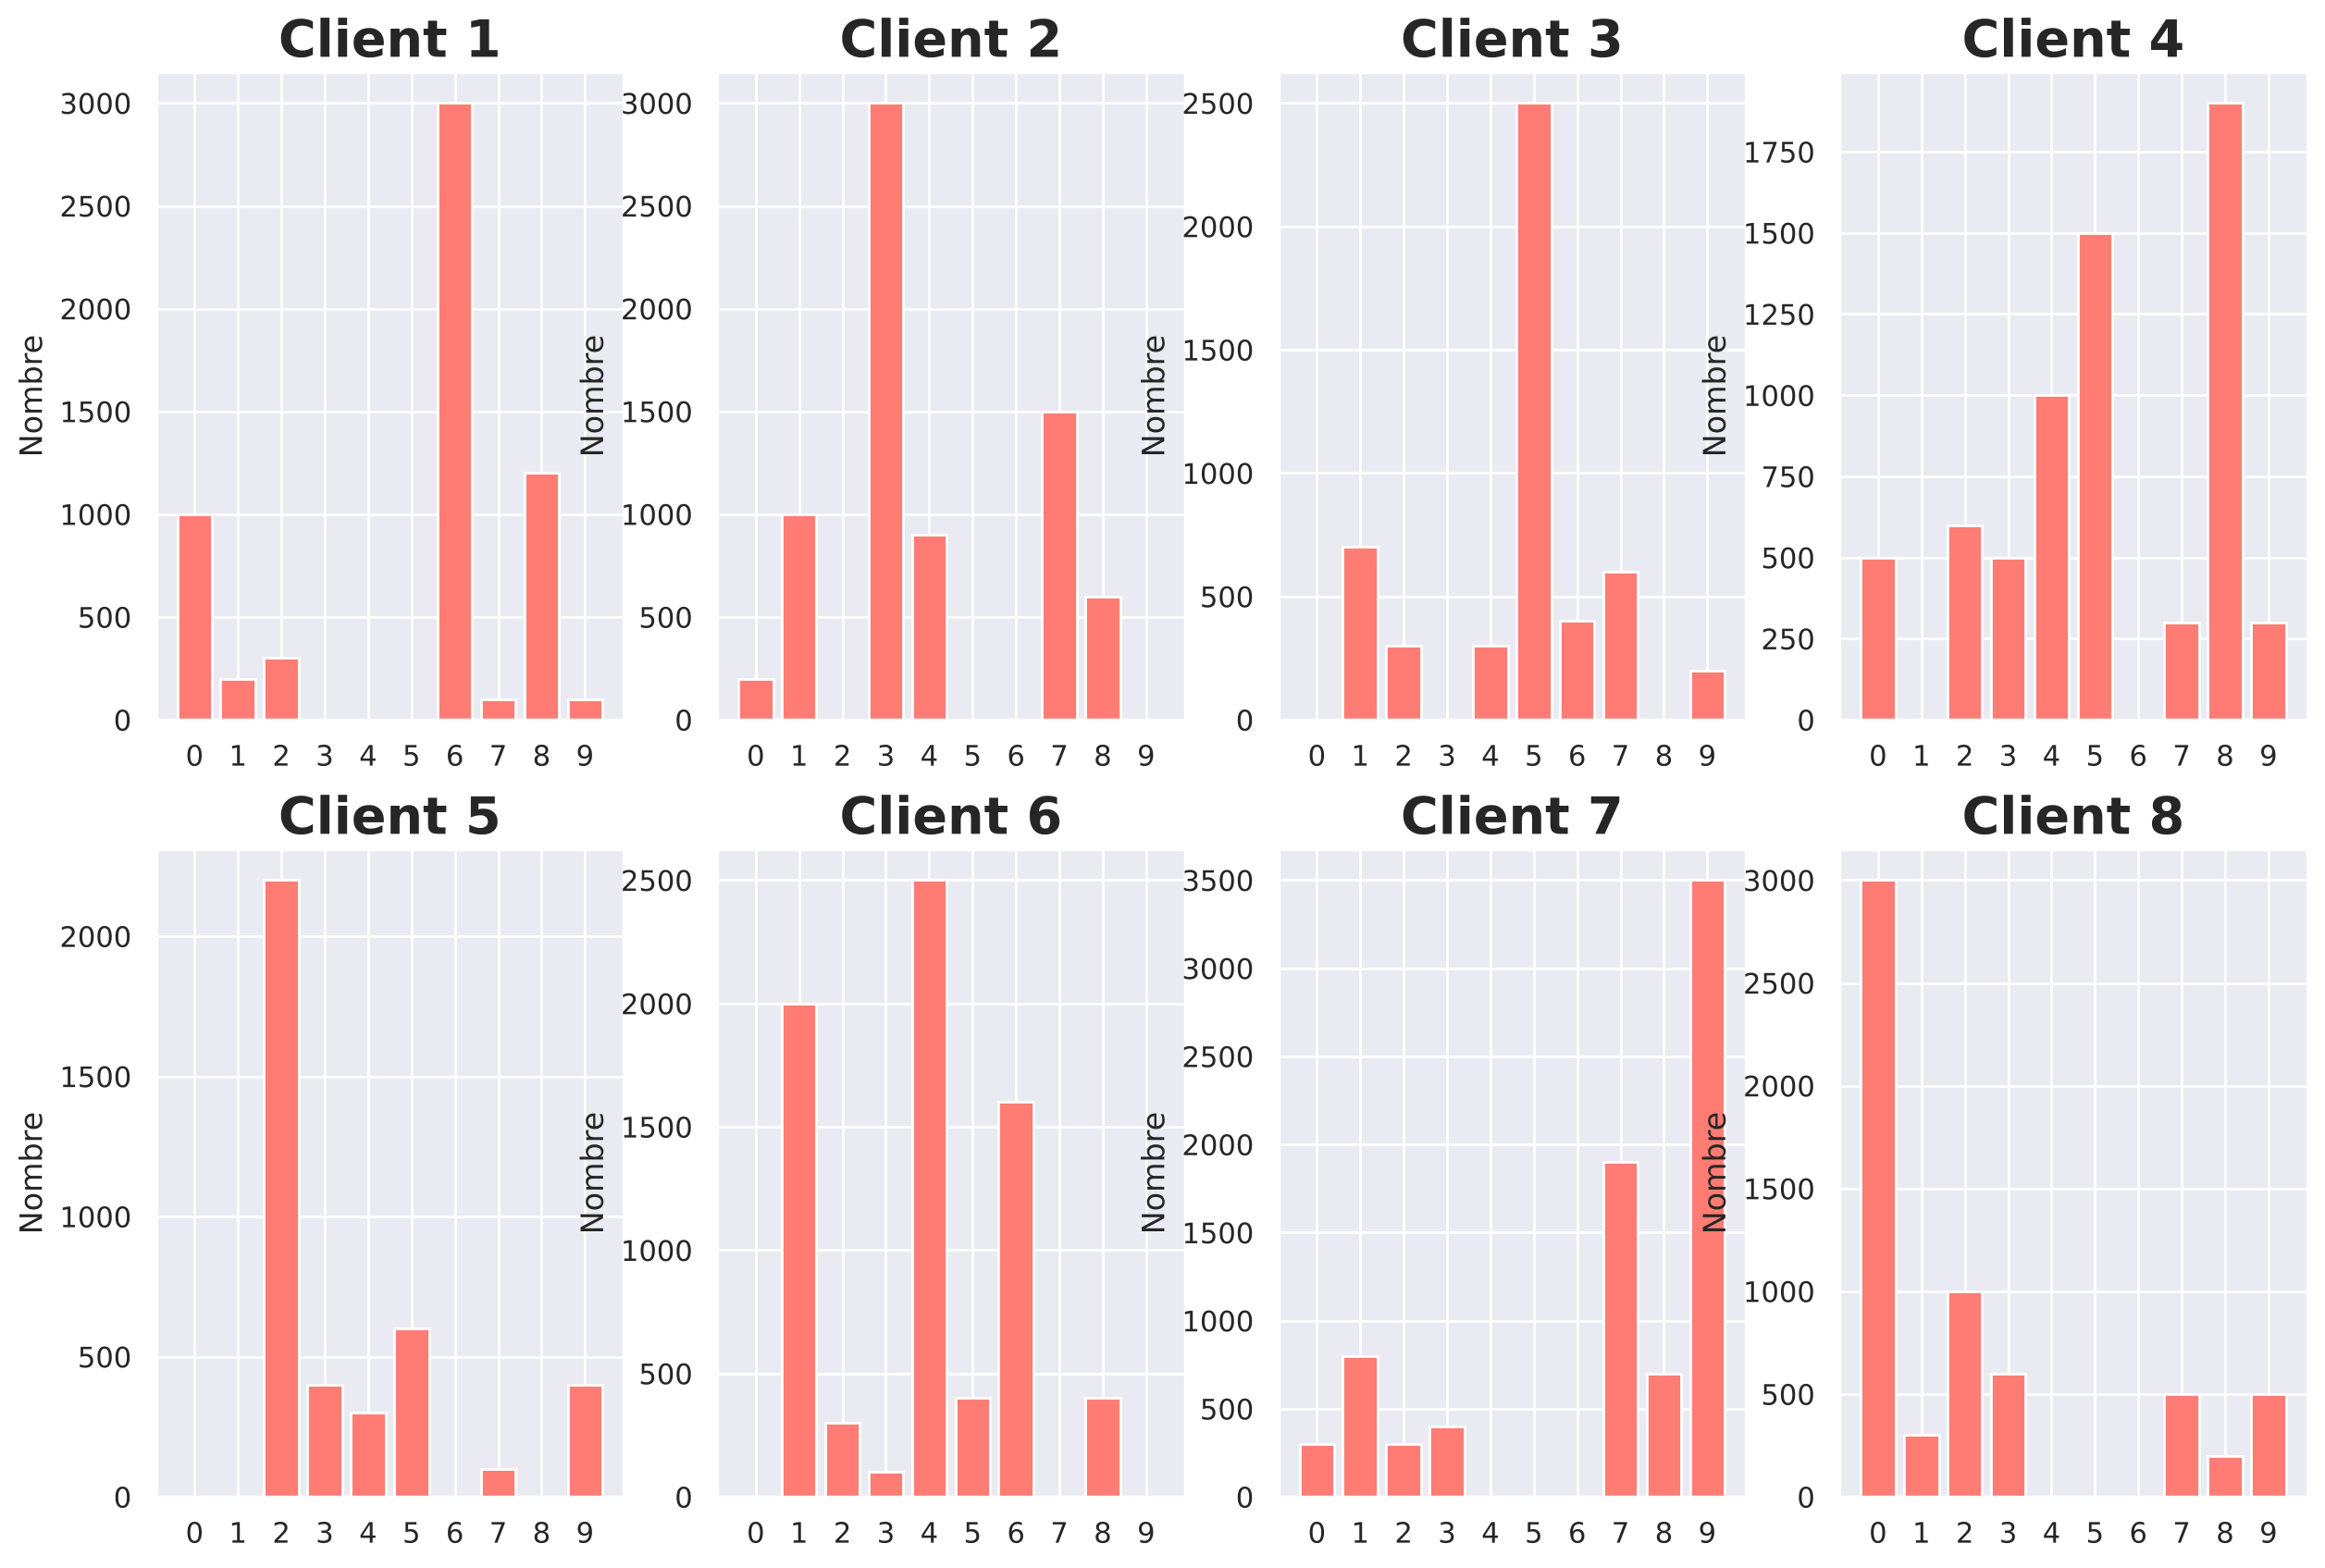

In [ ]:
fig, ax = plt.subplot_mosaic("ABCD;EFGH", figsize=(15, 10))
all_ax = list(ax.keys())
for idx, i in enumerate(distribution):
    plot_label_distribution(i, ax, all_ax[idx], idx)
    
plt.show()

## 13. Créer les jeux de données non IID

Pour chaque client, on tire dans CIFAR-10 le nombre d'images demandé pour chaque classe. Un décalage (`offsets`) garantit qu'**une image n'appartient qu'à un seul client**.

In [ ]:
# On réutilise CIFAR-10 déjà chargé (traindata), avec la même normalisation
targets = np.array(traindata.targets)

# Indices de chaque classe, mélangés (graine fixée pour retrouver le même découpage)
rng = np.random.default_rng(0)
class_indices = {c: rng.permutation(np.where(targets == c)[0]) for c in range(10)}
offsets = {c: 0 for c in range(10)}   # nombre d'images de la classe déjà distribuées

client_dataloaders = []
for client_index in range(len(distribution)):
    indices = []
    for class_index, count in enumerate(distribution[client_index]):
        start = offsets[class_index]
        indices.extend(class_indices[class_index][start:start + count].tolist())
        offsets[class_index] += count

    subset_dataset = Subset(traindata, indices)
    client_dataloaders.append(DataLoader(subset_dataset, batch_size=batch_size, shuffle=True))

print("Images par client :", [len(dl.dataset) for dl in client_dataloaders])

Images par client : [5900, 7200, 5000, 6600, 4000, 7300, 7900, 6100]


## 14. Entraîner sur des données non IID

Même boucle qu'à l'étape 8, mais avec les jeux déséquilibrés. Compare la précision obtenue à celle du cas IID : chaque client tire le modèle vers ses propres classes, et la moyenne des modèles est moins bonne que dans le cas IID.

In [ ]:
global_model = SimpleNet()

for round_no in range(num_rounds):

    total_loss = 0

    client_models = [deepcopy(global_model) for _ in range(num_clients)]

    for i in tqdm(range(num_clients), leave=False):
        optimizer = optim.Adam(client_models[i].parameters(), lr=0.001)
        client_models[i], local_loss = client_forward_pass(client_models[i], criterion, optimizer, client_dataloaders[i])
        total_loss += local_loss

    server_aggregate(global_model, client_models)

    print("Tour :", round_no + 1, "| Perte :", round(total_loss, 3), "| Précision :", round(evaluate(global_model), 4))

100%|██████████| 8/8 [00:11<00:00,  1.54s/it]


Tour : 1 | Perte : 999.048 | Précision : 0.2982


100%|██████████| 8/8 [00:11<00:00,  1.54s/it]


Tour : 2 | Perte : 939.016 | Précision : 0.3256


100%|██████████| 8/8 [00:12<00:00,  1.60s/it]


Tour : 3 | Perte : 893.225 | Précision : 0.366


... (50 outputs left out)

100%|██████████| 8/8 [00:12<00:00,  1.54s/it]


Tour : 29 | Perte : 540.42 | Précision : 0.5004


100%|██████████| 8/8 [00:11<00:00,  1.46s/it]


Tour : 30 | Perte : 531.822 | Précision : 0.5004


## 15. Un remède : un petit jeu de données commun

On suppose que le serveur dispose d'un **petit échantillon représentatif** (ici 1 000 images tirées au hasard, soit 2 % de CIFAR-10) qu'il peut partager avec tous les clients.

In [ ]:
def create_random_dataloader(cifar10_dataset, n):
    # Obtenir les indices de n échantillons aléatoires
    indices = torch.randperm(len(cifar10_dataset))[:n]
    
    # Créer un SubsetRandomSampler en utilisant les indices aléatoires
    sampler = torch.utils.data.SubsetRandomSampler(indices)
    
    # Créer un DataLoader en utilisant le SubsetRandomSampler
    dataloader = torch.utils.data.DataLoader(cifar10_dataset, batch_size=64, sampler=sampler)
    
    return dataloader

In [ ]:
common_data = create_random_dataloader(traindata, 1000)

## 16. Apprentissage fédéré avec entraînement supplémentaire

À chaque tour, après avoir appris sur ses données locales, chaque client s'entraîne **3 époques de plus** sur le jeu commun. Cela recentre les modèles sur toutes les classes avant l'agrégation. Compare avec l'étape 14 : la précision remonte-t-elle ? Dans notre exécution, le gain est très faible (de l'ordre de 0,3 point, dans la marge d'une exécution à l'autre) : 1 000 images partagées ne suffisent pas à contrer la dérive des clients. Tu peux essayer un jeu commun plus gros (`create_random_dataloader(traindata, 5000)`) pour voir si l'effet apparaît.

In [ ]:
global_model = SimpleNet()

for round_no in range(num_rounds):

    total_loss = 0

    client_models = [deepcopy(global_model) for _ in range(num_clients)]

    for i in tqdm(range(num_clients), leave=False):
        optimizer = optim.Adam(client_models[i].parameters(), lr=0.001)

        # Entraînement sur les données locales du client
        client_models[i], local_loss = client_forward_pass(client_models[i], criterion, optimizer, client_dataloaders[i])
        total_loss += local_loss

        # Entraînement supplémentaire (3 époques) sur le petit jeu commun
        client_models[i], _ = client_forward_pass(client_models[i], criterion, optimizer, common_data, epochs=3)

    server_aggregate(global_model, client_models)

    print("Tour :", round_no + 1, "| Perte :", round(total_loss, 3), "| Précision :", round(evaluate(global_model), 4))

100%|██████████| 8/8 [00:16<00:00,  2.09s/it]


Tour : 1 | Perte : 1005.978 | Précision : 0.2671


100%|██████████| 8/8 [00:17<00:00,  2.22s/it]


Tour : 2 | Perte : 967.834 | Précision : 0.3435


100%|██████████| 8/8 [00:16<00:00,  2.10s/it]


Tour : 3 | Perte : 905.184 | Précision : 0.403


... (50 outputs left out)

100%|██████████| 8/8 [00:15<00:00,  2.00s/it]


Tour : 29 | Perte : 559.306 | Précision : 0.5


100%|██████████| 8/8 [00:16<00:00,  2.07s/it]


Tour : 30 | Perte : 548.06 | Précision : 0.5037


## 17. Ce qu'il faut retenir

- L'apprentissage fédéré **déplace le modèle, pas les données** : seuls les poids circulent.
- Avec des données **IID**, le modèle global atteint le niveau d'un entraînement centralisé (autour de 55 % ici).
- Avec des données **non IID** (le cas réaliste), la précision chute d'environ 6 points : c'est le principal défi du domaine.
- Un **petit jeu de données commun** (1 000 images) utilisé pour un entraînement supplémentaire n'a presque rien récupéré ici : un remède doit se **mesurer**, pas se supposer. Essaie un jeu plus gros ou d'autres stratégies.
- Ici, le réseau est volontairement simple et sans réglage d'hyperparamètres : les précisions absolues sont faibles, ce sont les **écarts entre les scénarios** qui comptent.

---

## Pour aller plus loin

- [Compression de modèles : un levier clé pour un ML efficace](https://www.monshotdata.com/p/compression-modeles-machine-learning-efficace) — alléger un modèle avant de le déployer sur des appareils
- [Calibration des modèles ML (Partie 1)](https://www.monshotdata.com/p/calibration-modeles-machine-learning) — des probabilités fiables en production